# Surf Maneuver Recognition: Session-Grouped Split

The original split assigns clips to train, validation and test at random, so clips from the same session
(same surfer, spot and camera) end up on both sides (see `01_data_exploration.ipynb`, sections 6 to 8).
This notebook groups clips into sessions using visual similarity between consecutive clips,
then builds a new split where every session belongs to a single subset.

## 1. Clip table

The clip inventory is shared with the other notebooks through `src/data/inventory.py`.

In [3]:
import sys
from pathlib import Path

# Make the project root importable, so the notebook can use the code in src/
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data.inventory import build_clip_table

df = build_clip_table()
print(len(df), "clips")
df["source"].value_counts()

1062 clips


source
sequence_space         634
sequence_underscore    379
roller                  45
360                      4
Name: count, dtype: int64

## 2. Visual embeddings

Each clip is described by a DINOv2 embedding ([`facebook/dinov2-small`](https://huggingface.co/facebook/dinov2-small), Apache 2.0):
a 384-dimensional vector summarizing how the scene looks (sea, light, colors, framing).
To reduce noise from any single frame, we average the embeddings of three frames (25%, 50% and 75% of the clip).

In [4]:
import numpy as np
import torch
from transformers import AutoImageProcessor, AutoModel

from src.data.video import read_frame

MODEL_ID = "facebook/dinov2-small"
device = "cuda" if torch.cuda.is_available() else "cpu"

# The processor resizes and normalizes images the way the model was trained
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModel.from_pretrained(MODEL_ID).to(device).eval()
print("device:", device)

c:\Users\fabri\Desktop\Portfolio\surf-maneuver-recognition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1115 13:38:12.169000 228 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\Users\fabri\Desktop\Portfolio\surf-maneuver-recognition\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\fabri\.cache\huggingface\hub\models--facebook--dinov2-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For 

device: cuda


In [5]:
EMBEDDINGS_FILE = PROJECT_ROOT / "data" / "processed" / "dinov2_small_frame_embeddings.npz"
POSITIONS = (0.25, 0.5, 0.75)

# Computing takes a few minutes, so results are cached; the file list guards against stale caches
if EMBEDDINGS_FILE.exists() and list(np.load(EMBEDDINGS_FILE)["files"]) == df["file"].tolist():
    embeddings = np.load(EMBEDDINGS_FILE)["embeddings"]
else:
    vectors = []
    with torch.inference_mode():
        for path in df["path"]:
            frames = [read_frame(path, p) for p in POSITIONS]
            inputs = processor(images=frames, return_tensors="pt").to(device)
            per_frame = model(**inputs).pooler_output   # one 384-d vector per frame
            vectors.append(per_frame.mean(dim=0).cpu().numpy())
    embeddings = np.stack(vectors)
    EMBEDDINGS_FILE.parent.mkdir(parents=True, exist_ok=True)
    np.savez(EMBEDDINGS_FILE, embeddings=embeddings, files=np.array(df["file"]))

# Unit length, so a dot product between two clips is their cosine similarity
embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
embeddings.shape

(1062, 384)

## 3. Similarity between consecutive clips

Within a source, clips are ordered by number and compared with the next one (cosine similarity).
Consecutive clips from the same session should be very similar; a sharp drop marks a session boundary.
Random pairs of clips, mostly from different sessions, give the reference for "not similar".

In [6]:
# Order clips by source and number; clips without a number (e.g. "360.mp4") have no neighbors
ordered = df.dropna(subset=["clip_number"]).sort_values(["source", "clip_number"]).copy()
rows = ordered.index.to_numpy()   # positions in df, which are also the rows of `embeddings`

# Cosine similarity of each clip with the next one (dot product of unit vectors)
sim = (embeddings[rows[:-1]] * embeddings[rows[1:]]).sum(axis=1)

# The last clip of each source has no "next" clip in the same source
next_is_same_source = (ordered["source"].to_numpy()[:-1] == ordered["source"].to_numpy()[1:])
ordered["sim_next"] = np.append(np.where(next_is_same_source, sim, np.nan), np.nan)

ordered["sim_next"].describe().round(3)

count    1056.000
mean        0.876
std         0.076
min         0.356
25%         0.847
50%         0.895
75%         0.928
max         1.000
Name: sim_next, dtype: float64

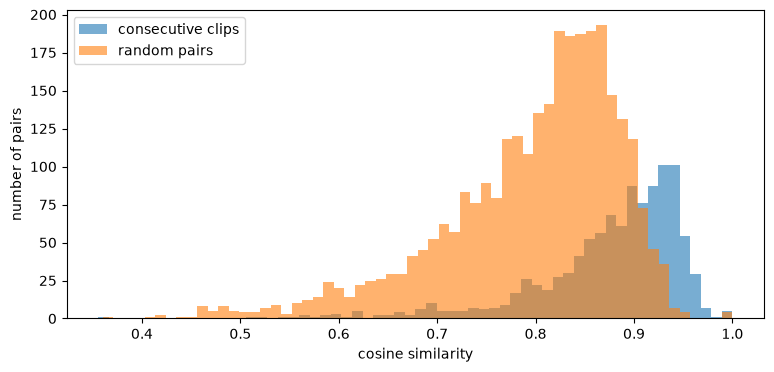

In [7]:
import matplotlib.pyplot as plt

# Reference: similarity between random pairs of clips (mostly different sessions)
rng = np.random.default_rng(0)
a, b = rng.integers(0, len(embeddings), size=(2, 3000))
random_sim = (embeddings[a] * embeddings[b]).sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ordered["sim_next"].dropna(), bins=60, alpha=0.6, label="consecutive clips")
ax.hist(random_sim, bins=60, alpha=0.6, label="random pairs")
ax.set_xlabel("cosine similarity")
ax.set_ylabel("number of pairs")
ax.legend()
plt.show()

The two distributions overlap heavily: every surf clip looks like every other surf clip (sea, foam, a person on a board),
so a single similarity threshold cannot separate sessions reliably. Consecutive clips are still more similar than random pairs
(median 0.895 vs about 0.83), which confirms that the numbering carries session information.
A few random pairs have a similarity close to 1.0, which suggests duplicate clips (next section).